<center><font size=10>AI-Based Plant Disease Detection System</center></font>

# Problem Statement

## Business Context

Crop diseases are one of the biggest reasons for yield loss in agriculture. Farmers often identify plant diseases late or incorrectly, because expert help is not always available and manual inspection is slow. Wrong or delayed treatment leads to heavy crop loss, wasted pesticides and lower income. Using Artificial Intelligence to analyze leaf images gives a fast and low-cost way to identify plant diseases early, so farmers can take the right action on time.

## Objective

This project aims to develop an AI-based system that detects plant diseases from leaf images using deep learning. The model identifies the crop and the disease (or confirms the leaf is healthy) from a single photo.

• Build a CNN model to classify leaf images into 38 classes (crop + disease / healthy).

• Compare a custom CNN with a transfer learning model (MobileNetV2).

• Select the best model and save it for deployment.

• Use the saved model in a Streamlit web app for real-time prediction.

## Data Description

The dataset is the **New Plant Diseases Dataset (Augmented)** from Kaggle, based on PlantVillage. It contains RGB images of healthy and diseased leaves from 14 crops such as Apple, Tomato, Potato, Corn and Grape.

- **train** folder: ~70,000 images, 38 class folders
- **valid** folder: ~17,500 images, 38 class folders

Each folder name is the label, for example `Tomato___Late_blight` or `Apple___healthy`.

# Importing the Necessary Libraries

In [ ]:
!pip install -q kagglehub

In [ ]:
# Libraries for data analysis and visualization
import os
import time
import gc
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

# Libraries for building and evaluating the deep learning model
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, recall_score

In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

Setting a random seed ensures that random processes like weight initialization and data shuffling give the same results every time, helping with consistent comparisons.

# Loading the Data

Make sure the Colab runtime is set to **GPU** (Runtime → Change runtime type → T4 GPU).

In [ ]:
import kagglehub

path = kagglehub.dataset_download("vipoooool/new-plant-diseases-dataset")
print(path)

Using Colab cache for faster access to the 'new-plant-diseases-dataset' dataset.
/kaggle/input/new-plant-diseases-dataset


In [ ]:
base = os.path.join(path, "New Plant Diseases Dataset(Augmented)",
                    "New Plant Diseases Dataset(Augmented)")
train_dir = os.path.join(base, "train")
valid_dir = os.path.join(base, "valid")
print(os.listdir(base))

['valid', 'train']


# Data Overview

In [ ]:
class_names = sorted(os.listdir(train_dir))
print("Number of classes:", len(class_names))

train_counts = {c: len(os.listdir(os.path.join(train_dir, c))) for c in class_names}
valid_counts = {c: len(os.listdir(os.path.join(valid_dir, c))) for c in class_names}

print("Total training images  :", sum(train_counts.values()))
print("Total validation images:", sum(valid_counts.values()))

Number of classes: 38
Total training images  : 70295
Total validation images: 17572


- **Number of Classes**: 38 (each class is a crop + disease or crop + healthy).
- **Image Size**: Original images are 256 x 256 pixels with 3 color channels (RGB). We will resize them to 224 x 224 for the model.
- **Train / Valid**: The `valid` folder will be split into validation and test sets so that the model is tested on images it never saw.

# Exploratory Data Analysis

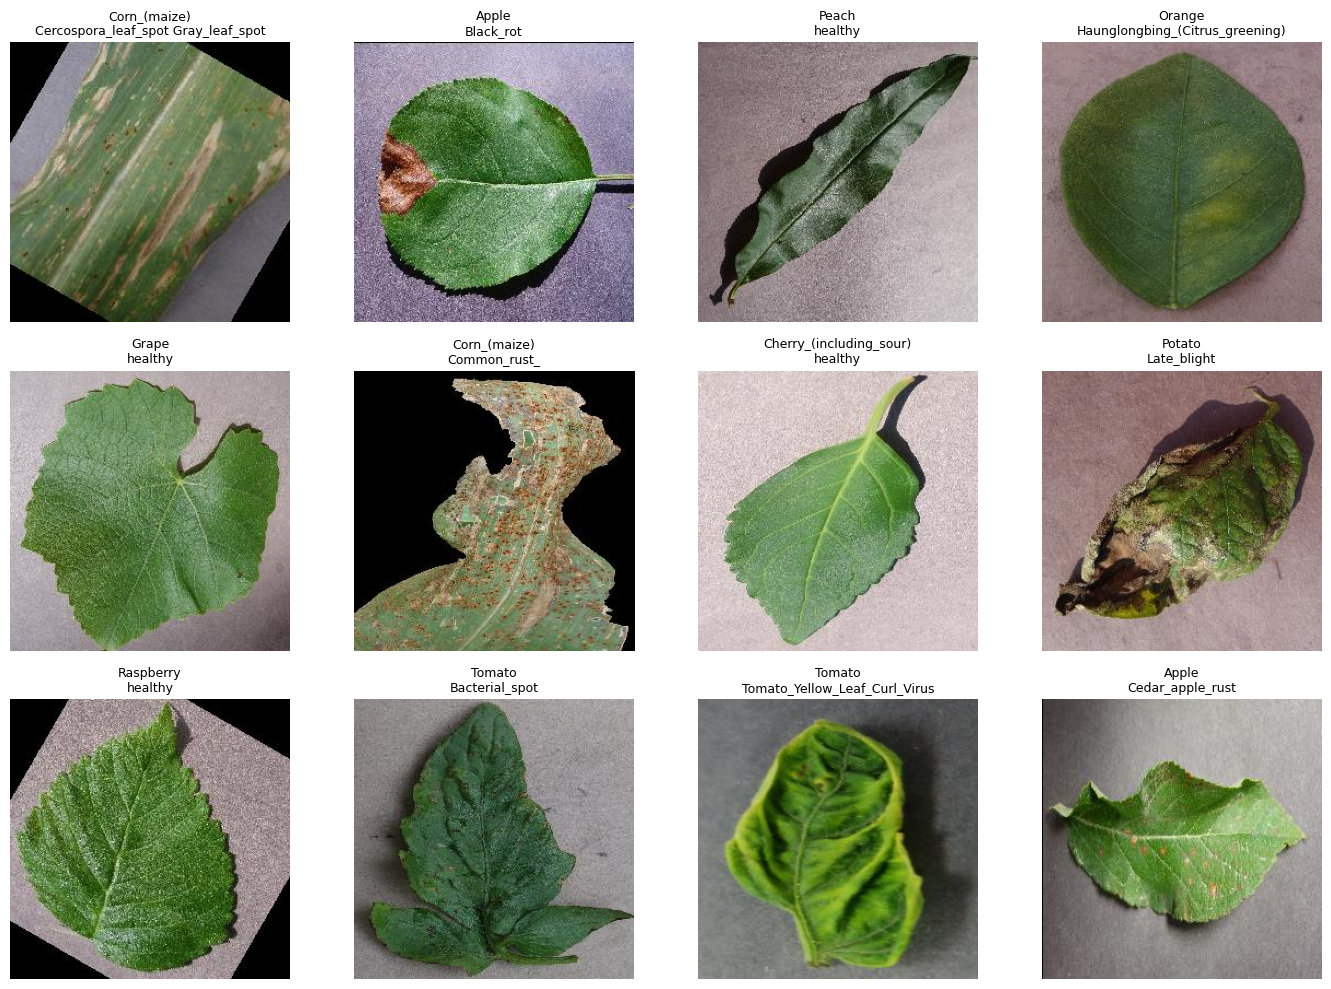

In [ ]:
# Visualize 12 images from different classes in a 3x4 grid layout
sample_classes = random.sample(class_names, 12)

plt.figure(figsize=(14, 10))
for i, cls in enumerate(sample_classes):
    cls_dir = os.path.join(train_dir, cls)
    img_name = random.choice(os.listdir(cls_dir))
    img = mpimg.imread(os.path.join(cls_dir, img_name))
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(cls.replace("___", "\n"), fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

/tmp/ipykernel_503/1390265517.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(train_counts.values()), y=list(train_counts.keys()), palette="viridis")


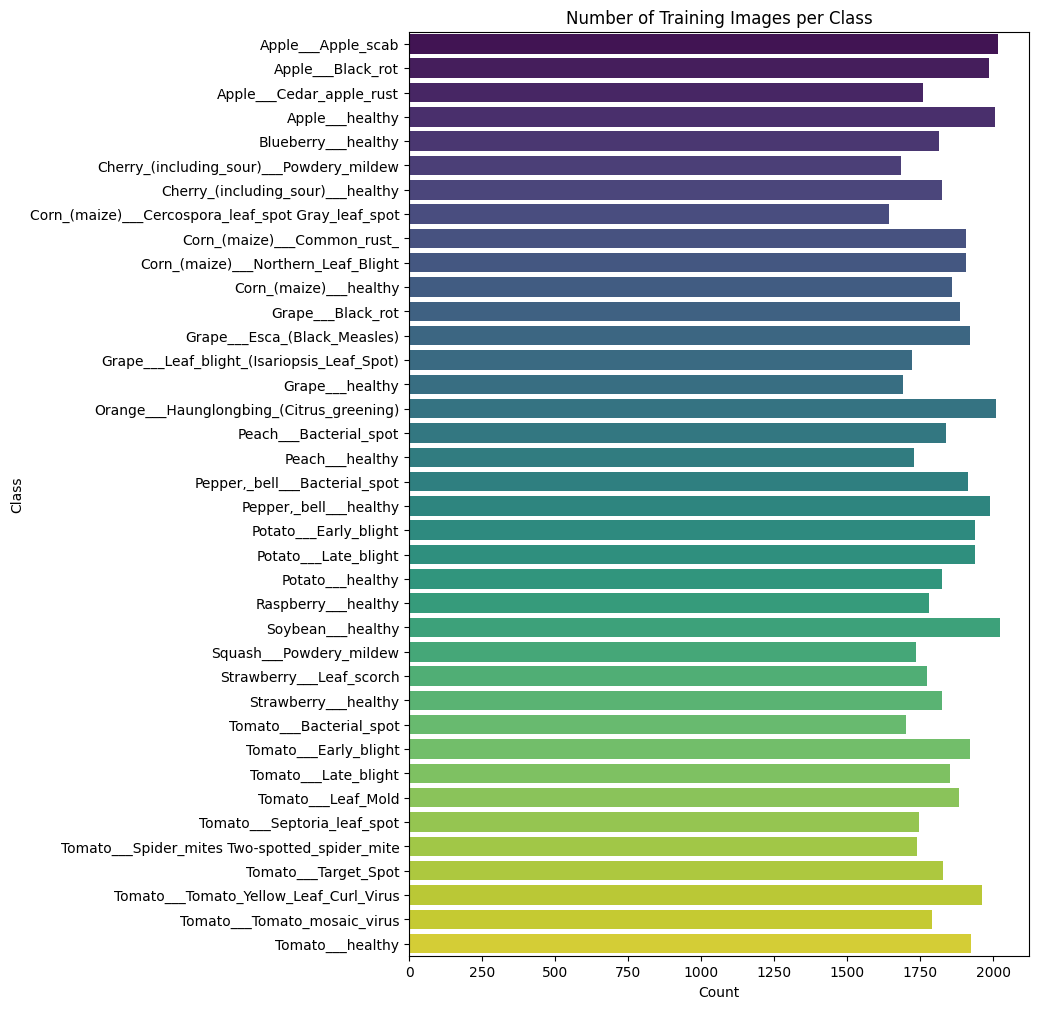

In [ ]:
# Visualize the number of training images in each class
plt.figure(figsize=(8, 12))
sns.barplot(x=list(train_counts.values()), y=list(train_counts.keys()), palette="viridis")
plt.title("Number of Training Images per Class")
plt.xlabel("Count")
plt.ylabel("Class")
plt.show()

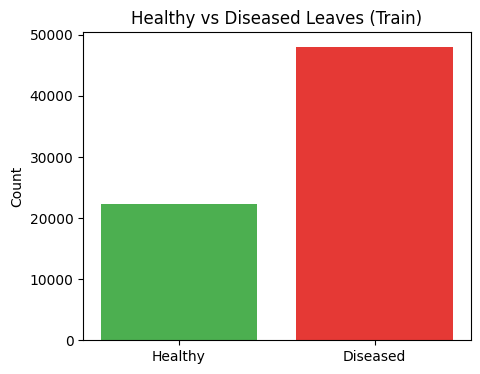

In [ ]:
# Healthy vs diseased leaves
healthy = sum(v for k, v in train_counts.items() if "healthy" in k.lower())
diseased = sum(train_counts.values()) - healthy

plt.figure(figsize=(5, 4))
plt.bar(["Healthy", "Diseased"], [healthy, diseased], color=["#4CAF50", "#E53935"])
plt.title("Healthy vs Diseased Leaves (Train)")
plt.ylabel("Count")
plt.show()

**Observation:**

* The classes are almost balanced (about 1,800 images per class), so accuracy is a reliable metric here.
* Diseased leaves are more than healthy leaves, because most classes are diseases. (Write your own observation after running the cells.)

# Data Preprocessing

In [ ]:
IMG_SIZE = (224, 224)
BATCH = 32

train_ds = keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH,
    shuffle=True, seed=SEED)

# Split the valid folder into validation and test sets (50:50)
val_ds, test_ds = keras.utils.image_dataset_from_directory(
    valid_dir, image_size=IMG_SIZE, batch_size=BATCH,
    shuffle=True, seed=SEED, validation_split=0.5, subset="both")

class_names = train_ds.class_names
print("Classes:", len(class_names))

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 70295 files belonging to 38 classes.
Found 17572 files belonging to 38 classes.
Using 8786 files for training.
Using 8786 files for validation.
Classes: 38


## Data Normalization

Raw pixel values range from 0 to 255. Scaling them to a smaller range helps the network train faster and more stably. Our method of normalization here is **scaling**:

- **CNN Model 1** uses a `Rescaling(1/255)` layer, so pixel values become 0-1.
- **MobileNetV2** was trained with inputs in the range -1 to 1, so we use `Rescaling(1/127.5, offset=-1)`.

Both layers are part of the model itself, so the saved model accepts raw images directly. This makes deployment in Streamlit easy.

# Model Building

Two models are compared and the best-performing one is selected:

• **CNN Model 1**: a custom CNN built from scratch with 3 Conv + Pooling blocks.

• **CNN Model 2**: transfer learning with MobileNetV2 (pre-trained on ImageNet), with a new classification head for 38 classes.

Note

Results may vary across runs because of random initialization. Saving the final trained model ensures consistent results for future inference.

## Model Evaluation Criteria

1. **Overall Accuracy**
   Percentage of all leaf images classified correctly across the 38 classes.

   *Usefulness:* Gives a general view of how well the model performs. Since classes are balanced, accuracy is reliable.

2. **Macro Recall**
   Average recall across all 38 classes (how many actual leaves of each class are correctly found).

   *Usefulness:* Missing a diseased leaf is costly for a farmer. Macro recall makes sure no single disease class is ignored.

In [ ]:
evaluation_result = pd.DataFrame(columns=['Model Name', 'Train Accuracy', 'Validation Accuracy', 'Validation Macro Recall'])

In [ ]:
# Helper function: collect true and predicted labels in a single pass
def get_predictions(model, ds):
    y_true, y_pred = [], []
    for images, labels in ds:
        probs = model(images, training=False).numpy()
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(probs, axis=1))
    return np.array(y_true), np.array(y_pred)

## CNN Model 1

In [ ]:
# Clear Keras session
tf.keras.backend.clear_session()
gc.collect()

11036

In [ ]:
model_cnn1 = Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),

    # Combination 1: Conv + Pooling
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Combination 2: Conv + Pooling
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Combination 3: Conv + Pooling
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    # Hidden layer
    layers.Dense(128, activation='relu'),

    # Output layer: 38 classes with softmax
    layers.Dense(len(class_names), activation='softmax')
])

model_cnn1.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

model_cnn1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,943,334 (49.37 MB)

 Trainable params: 12,943,334 (49.37 MB)

 Non-trainable params: 0 (0.00 B)

Here's a short explanation of the key choices:

* **Conv2D(32, (3, 3), relu, same)**: 32 filters of size 3x3 detect patterns such as edges and spots; ReLU adds non-linearity; `same` padding keeps the size unchanged.
* **MaxPooling2D((2, 2))**: halves the height and width, reducing computation and overfitting.
* **Dense(38, softmax)**: gives a probability for each of the 38 classes.
* **sparse_categorical_crossentropy**: used because labels are integers (0 to 37) for a multi-class problem.

In [ ]:
start_time = time.time()

history1 = model_cnn1.fit(train_ds,
                          validation_data=val_ds,
                          epochs=5)

training_time = time.time() - start_time
print(f"Training completed in {training_time:.2f} seconds.")

Epoch 1/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 329s 144ms/step - accuracy: 0.6244 - loss: 1.3397 - val_accuracy: 0.7908 - val_loss: 0.7140
Epoch 2/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 138s 63ms/step - accuracy: 0.8258 - loss: 0.5775 - val_accuracy: 0.8532 - val_loss: 0.4971
Epoch 3/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 137s 62ms/step - accuracy: 0.8778 - loss: 0.4018 - val_accuracy: 0.8605 - val_loss: 0.4586
Epoch 4/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 138s 63ms/step - accuracy: 0.9068 - loss: 0.2989 - val_accuracy: 0.8599 - val_loss: 0.4542
Epoch 5/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 137s 63ms/step - accuracy: 0.9306 - loss: 0.2238 - val_accuracy: 0.8953 - val_loss: 0.3323
Training completed in 880.22 seconds.


In [ ]:
# Evaluate on validation data
y_val_true, y_val_pred = get_predictions(model_cnn1, val_ds)

train_acc = history1.history['accuracy'][-1]
val_acc = accuracy_score(y_val_true, y_val_pred)
val_recall = recall_score(y_val_true, y_val_pred, average='macro')

new_row = pd.DataFrame([{
    'Model Name': 'CNN Model 1 (3 Conv Layers)',
    'Train Accuracy': train_acc,
    'Validation Accuracy': val_acc,
    'Validation Macro Recall': val_recall
}])
evaluation_result = pd.concat([evaluation_result, new_row], ignore_index=True)

print("Evaluation Results:")
evaluation_result

Evaluation Results:


/tmp/ipykernel_503/2968712863.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_result = pd.concat([evaluation_result, new_row], ignore_index=True)


,Model Name,Train Accuracy,Validation Accuracy,Validation Macro Recall
0,CNN Model 1 (3 Conv Layers),0.930649,0.895288,0.894793


**Observation:**

(Write after running: compare training accuracy and validation accuracy. If training accuracy is much higher than validation accuracy, the model is overfitting.)

## CNN Model 2 (Transfer Learning with MobileNetV2)

A custom CNN has to learn everything from scratch. **MobileNetV2** is already trained on millions of ImageNet images, so it already knows edges, textures and shapes. We freeze it and train only a new classification head. This usually gives higher accuracy, faster training and better generalization.

* **Frozen base**: pre-trained weights are kept unchanged.
* **GlobalAveragePooling2D**: converts feature maps into a compact vector.
* **Dropout(0.3)**: reduces overfitting.

In [ ]:
# Clear Keras session
tf.keras.backend.clear_session()
gc.collect()

0

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False

model_mnv2 = Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./127.5, offset=-1),   # MobileNetV2 expects inputs in [-1, 1]
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')
])

model_mnv2.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

model_mnv2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
start_time = time.time()

history2 = model_mnv2.fit(train_ds,
                          validation_data=val_ds,
                          epochs=5)

training_time = time.time() - start_time
print(f"Training completed in {training_time:.2f} seconds.")

Epoch 1/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 170s 66ms/step - accuracy: 0.8750 - loss: 0.4355 - val_accuracy: 0.9392 - val_loss: 0.1902
Epoch 2/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 107s 49ms/step - accuracy: 0.9347 - loss: 0.2011 - val_accuracy: 0.9505 - val_loss: 0.1537
Epoch 3/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 141s 48ms/step - accuracy: 0.9432 - loss: 0.1716 - val_accuracy: 0.9512 - val_loss: 0.1439
Epoch 4/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 150s 52ms/step - accuracy: 0.9468 - loss: 0.1570 - val_accuracy: 0.9564 - val_loss: 0.1368
Epoch 5/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 132s 47ms/step - accuracy: 0.9489 - loss: 0.1502 - val_accuracy: 0.9572 - val_loss: 0.1291
Training completed in 699.71 seconds.


In [ ]:
# Evaluate on validation data
y_val_true, y_val_pred = get_predictions(model_mnv2, val_ds)

train_acc = history2.history['accuracy'][-1]
val_acc = accuracy_score(y_val_true, y_val_pred)
val_recall = recall_score(y_val_true, y_val_pred, average='macro')

new_row = pd.DataFrame([{
    'Model Name': 'CNN Model 2 (MobileNetV2)',
    'Train Accuracy': train_acc,
    'Validation Accuracy': val_acc,
    'Validation Macro Recall': val_recall
}])
evaluation_result = pd.concat([evaluation_result, new_row], ignore_index=True)

print("Evaluation Results:")
evaluation_result

Evaluation Results:


,Model Name,Train Accuracy,Validation Accuracy,Validation Macro Recall
0,CNN Model 1 (3 Conv Layers),0.930649,0.895288,0.894793
1,CNN Model 2 (MobileNetV2),0.948944,0.957205,0.956414


**Observation:**

(Write after running: note the validation accuracy and macro recall of MobileNetV2, and whether it generalizes better than Model 1.)

# Model Performance Comparison and Final Model Selection

The two models are compared on validation accuracy and macro recall. The model with higher validation performance and a small gap between training and validation accuracy generalizes better, so it is selected as the **final model**. (MobileNetV2 is generally expected to win; confirm with your table.)

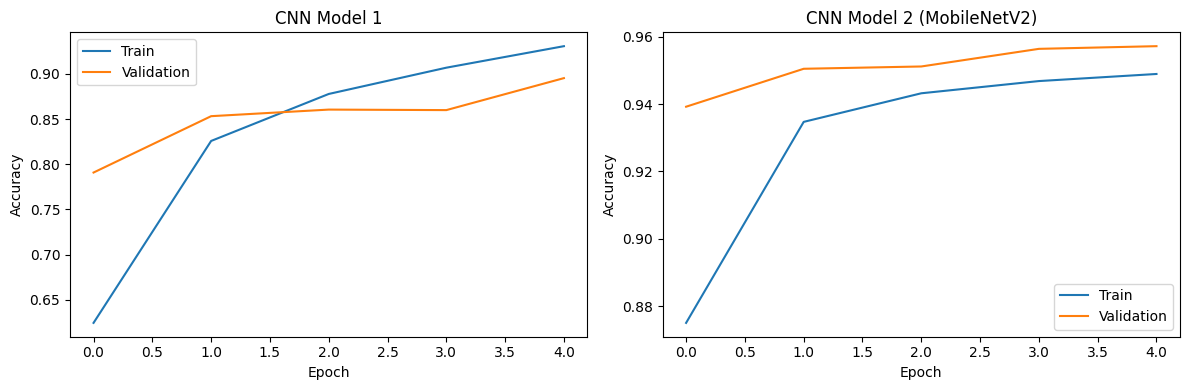

In [ ]:
# Training curves of both models
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history1.history['accuracy'], label='Train')
ax[0].plot(history1.history['val_accuracy'], label='Validation')
ax[0].set_title('CNN Model 1')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy'); ax[0].legend()

ax[1].plot(history2.history['accuracy'], label='Train')
ax[1].plot(history2.history['val_accuracy'], label='Validation')
ax[1].set_title('CNN Model 2 (MobileNetV2)')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Select the final model (change this if Model 1 performs better in your table)
final_model = model_mnv2

## Test Performance

In [ ]:
y_test_true, y_test_pred = get_predictions(final_model, test_ds)

test_acc = accuracy_score(y_test_true, y_test_pred)
test_recall = recall_score(y_test_true, y_test_pred, average='macro')

print(f"Test Accuracy    : {test_acc:.4f}")
print(f"Test Macro Recall: {test_recall:.4f}")

Test Accuracy    : 0.9562
Test Macro Recall: 0.9563


In [ ]:
# Detailed per-class report
print(classification_report(y_test_true, y_test_pred, target_names=class_names))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.98      0.98       248
                                 Apple___Black_rot       0.98      1.00      0.99       269
                          Apple___Cedar_apple_rust       0.98      0.99      0.99       220
                                   Apple___healthy       0.99      0.99      0.99       252
                               Blueberry___healthy       1.00      1.00      1.00       226
          Cherry_(including_sour)___Powdery_mildew       1.00      0.98      0.99       210
                 Cherry_(including_sour)___healthy       0.99      0.99      0.99       224
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.90      0.91      0.90       192
                       Corn_(maize)___Common_rust_       0.99      1.00      0.99       243
               Corn_(maize)___Northern_Leaf_Blight       0.94      0.92      0.

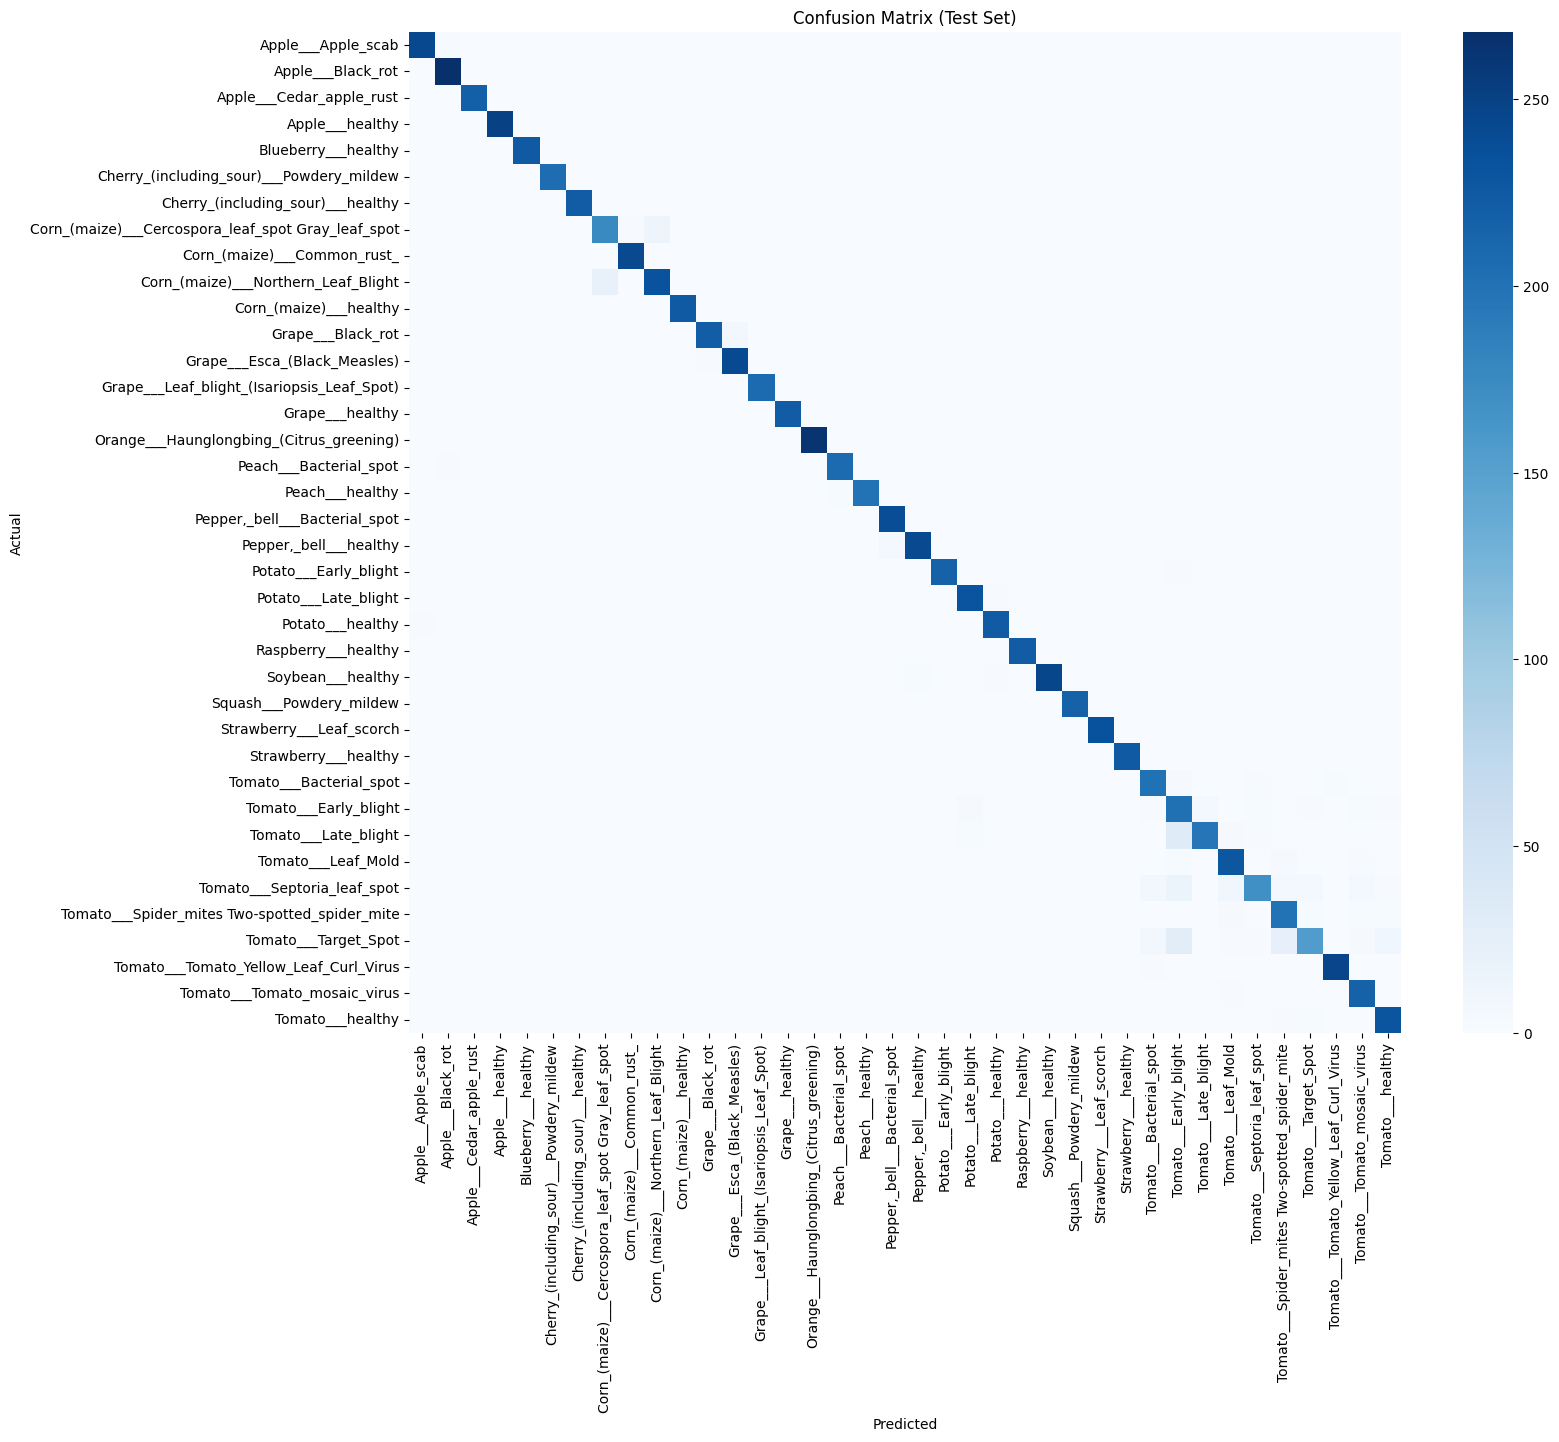

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test_true, y_test_pred)

plt.figure(figsize=(16, 13))
sns.heatmap(cm, cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**Observation**

(Write after running: state the test accuracy and macro recall, and mention any classes that are often confused, for example similar-looking tomato diseases.)

## Prediction

1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step


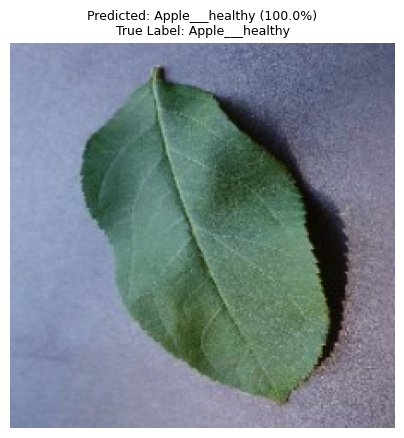

In [ ]:
# Take one batch from the test set and predict the first image
for images, labels in test_ds.take(1):
    sample_image = images[0]
    sample_true_label = int(labels[0])

sample_image_batch = np.expand_dims(sample_image.numpy(), axis=0)
probs = final_model.predict(sample_image_batch)[0]
pred_idx = int(np.argmax(probs))

plt.figure(figsize=(5, 5))
plt.imshow(sample_image.numpy().astype("uint8"))
plt.title(f"Predicted: {class_names[pred_idx]} ({probs[pred_idx]*100:.1f}%)\n"
          f"True Label: {class_names[sample_true_label]}", fontsize=9)
plt.axis('off')
plt.show()

# Saving the Model

The trained model and the class names are saved so that the Streamlit app can load them without retraining.

In [ ]:
final_model.save("plant_disease_model.keras")

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

# Download both files from Colab
from google.colab import files
files.download("plant_disease_model.keras")
files.download("class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusion

• A deep learning model was successfully developed to classify leaf images into 38 plant disease and healthy classes.

• Transfer learning with MobileNetV2 gives a strong, lightweight model suitable for web and mobile deployment.

• The saved model will be used in a Streamlit app where a farmer uploads a leaf photo and gets the disease name with a confidence score.

• Future improvements: fine-tune the top MobileNetV2 layers, test with real field photos (not only lab images), and add treatment suggestions for each disease.

<font size=5.5 color="#4682B4"><b>Power Ahead!</font>
___